In [1]:
"""
Plot TF expression, motif enrichment and AUC values of target genes and regions in a dotplot.

"""

import pandas as pd
from plotnine import (
    ggplot, geom_point, aes, scale_fill_distiller, 
    geom_tile, theme, element_text, element_blank)
from plotnine.facets import facet_grid
import plotnine
from typing import List, Union, Optional, Tuple
from mudata import MuData
from scenicplus.scenicplus_mudata import ScenicPlusMuData
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

def _scale(X: pd.DataFrame) -> pd.DataFrame:
    return (X - X.min()) / (X.max() - X.min())

def z_scale(df):
    scaler = StandardScaler()
    df = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)
    return df
    
import math


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/scenicplus/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


In [2]:
rss_df = pd.read_csv('rss.csv', index_col=0)
tf_df = pd.read_csv('tf_exp.csv', index_col=0)

rss_df = z_scale(rss_df)

import json
with open('/home/rsun@ZHANGroup.local/sly_data/sly_06_require/leiden_dic.json', 'r') as f:
    cluster_dic = json.load(f)

rss_df.index = rss_df.index.astype(str)
rss_df.index = rss_df.index.map(cluster_dic)
tf_df.index = tf_df.index.astype(str)
tf_df.index = tf_df.index.map(cluster_dic)


In [33]:

HEATMAP_COLOR_MIN = rss_df.values.min()
HEATMAP_COLOR_MAX = rss_df.values.max()
HEATMAP_CMAP = "RdYlBu_r" # 从蓝色到红色，_r 表示反转

# Dot plot 大小映射参数
DOT_MIN_VALUE = 0 # 只有当 dot_df 值大于等于此阈值时才绘制点
DOT_SIZE_BASE = 50   # 点的最小面积 (pixels)
DOT_SIZE_SCALE_FACTOR = 400 # 映射到点面积的缩放因子


dot_legend_thresholds = {
    #'<-0.5': 0.5, # 用于在图例中表示
    '0-0.5': 0,
    '0.5-1.0': 0.5,
    '1.0-1.5': 1.0,
    '1.5-2.0': 1.5,
    '>2.0': 2.0
}


# --- 3. 抽象绘制函数 (与之前相同，它本身就是通用的) ---
def plot_abstract_heatmap_dots(
    ax,
    heatmap_df: pd.DataFrame,
    dotplot_df: pd.DataFrame,
    title: str,
    heatmap_color_min: float,
    heatmap_color_max: float,
    heatmap_cmap: str,
    dot_min_value: float,
    dot_size_base: float,
    dot_size_scale_factor: float
):
    """
    绘制抽象的 Dot plot + Heatmap 组合图。

    Args:
        ax (matplotlib.axes.Axes): 要在其上绘图的 Axes 对象。
        heatmap_df (pd.DataFrame): 决定热力图颜色的 DataFrame。
        dotplot_df (pd.DataFrame): 决定点大小的 DataFrame，与 heatmap_df 形状相同。
        title (str): 子图的标题。
        sample_colors (dict): 字典，映射 sample_label 到颜色。
        feature_colors (dict): 字典，映射 feature_label 到颜色。
        heatmap_color_min (float): 热力图颜色映射的最小值。
        heatmap_color_max (float): 热力图颜色映射的最大值。
        heatmap_cmap (str): 热力图的 Colormap 名称。
        dot_min_value (float): 只有当 dotplot_df 值大于等于此阈值时才绘制点。
        dot_size_base (float): 点的最小面积 (pixels)。
        dot_size_scale_factor (float): 映射到点面积的缩放因子。
    """
    # 确保两个 DataFrame 的索引和列顺序一致
    if not heatmap_df.index.equals(dotplot_df.index) or \
       not heatmap_df.columns.equals(dotplot_df.columns):
        raise ValueError("heatmap_df and dotplot_df must have identical indices and columns.")

    # 绘制 Heatmap
    sns.heatmap(
        heatmap_df,
        ax=ax,
        cmap=heatmap_cmap,
        cbar=False,
        vmin=heatmap_color_min,
        vmax=heatmap_color_max,
        linewidths=0.5,
        linecolor='lightgray',
    )

    # 绘制 Dots
    # 遍历每个单元格来绘制点
    for i, sample_label in enumerate(heatmap_df.index):
        for j, feature_label in enumerate(heatmap_df.columns):
            dot_val = dotplot_df.loc[sample_label, feature_label]

            # 只有当 dot_val 达到一定阈值时才绘制点
            if dot_val >= dot_min_value:
                # 映射 dot_val 到点的大小 (面积)
                # 假设 dot_min_value 到 dotplot_df.max().max() 是点大小的有效范围
                normalized_dot_val = (dot_val - dot_min_value) / (dotplot_df.max().max() - dot_min_value)
                
                s = math.sqrt(normalized_dot_val) * dot_size_scale_factor + dot_size_base

                ax.scatter(j + 0.5, i + 0.5, s=s, color='black', edgecolor='black', zorder=2)

    ax.set_title(title, loc='right', fontsize=18, va='center')
    ax.tick_params(axis='y', rotation=0)
    ax.tick_params(axis='x', rotation=90)


    # 隐藏坐标轴刻度线和标签
    ax.tick_params(axis='both', which='both', length=0)
    ax.set_xlabel('')
    ax.set_ylabel('')




In [39]:
new_idx = [f'cluster {i}' for i in range(1,12)]
rss_df = rss_df.loc[new_idx,:]
tf_df = tf_df.loc[new_idx,:]

/tmp/ipykernel_3029069/586243029.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


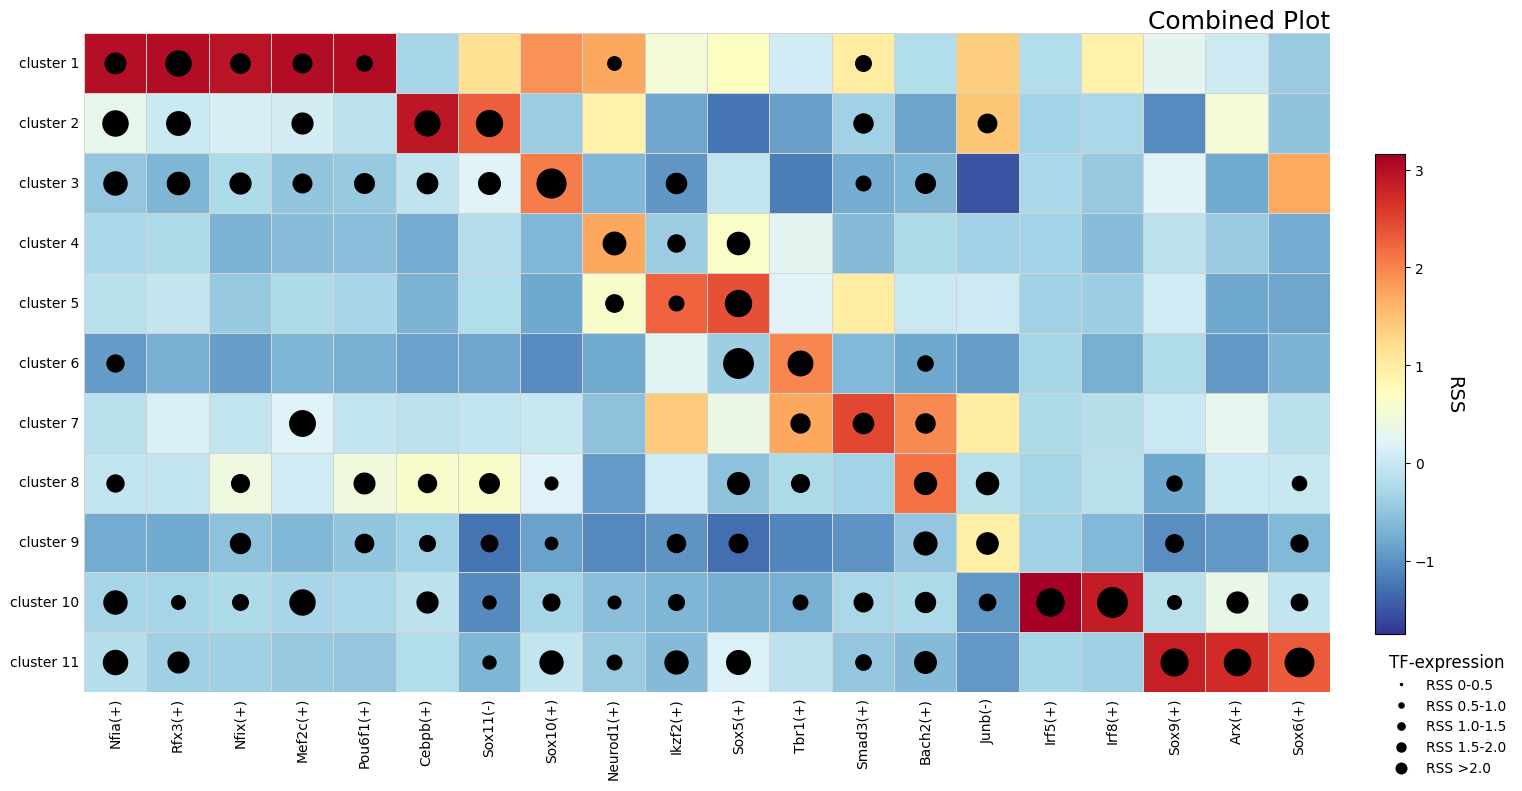

In [44]:
tf_list = ['Nfia(+)','Rfx3(+)','Nfix(+)','Mef2c(+)','Pou6f1(+)','Cebpb(+)','Sox11(-)','Sox10(+)','Neurod1(+)','Ikzf2(+)','Sox5(+)','Tbr1(+)','Smad3(+)',
            'Bach2(+)','Junb(-)','Irf5(+)','Irf8(+)','Sox9(+)','Arx(+)', 'Sox6(+)']

# --- 4. 绘制单张图 ---
fig, ax = plt.subplots(1, 1, figsize=(15, 8)) # 只创建一个图和 Axes 对象，调整整体大小

# 绘制数据
plot_abstract_heatmap_dots(
    ax=ax,
    heatmap_df=rss_df.loc[:,tf_list],
    dotplot_df=tf_df.loc[:,tf_list],
    title='Combined Plot', # 单张图的标题
    heatmap_color_min=HEATMAP_COLOR_MIN,
    heatmap_color_max=HEATMAP_COLOR_MAX,
    heatmap_cmap=HEATMAP_CMAP,
    dot_min_value=DOT_MIN_VALUE,
    dot_size_base=DOT_SIZE_BASE,
    dot_size_scale_factor=DOT_SIZE_SCALE_FACTOR
)

# --- 5. 添加公共颜色条和图例 (位置需要调整以适应单张图) ---

# Heatmap 颜色条
# 调整颜色条的位置，使其在单张图旁边
cbar_ax = fig.add_axes([0.92, 0.2, 0.02, 0.6]) # [left, bottom, width, height]
norm = plt.Normalize(vmin=HEATMAP_COLOR_MIN, vmax=HEATMAP_COLOR_MAX)
sm = plt.cm.ScalarMappable(cmap=HEATMAP_CMAP, norm=norm)
sm.set_array([]) # 必需设置一个空数组
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('RSS', rotation=270, labelpad=20, fontsize=14)
cbar.ax.tick_params(labelsize=10)

# Dot plot 大小图例
# 调整图例的位置，使其在单张图旁边
legend_elements = []
max_dot_val_for_legend = tf_df.max().max() # 获取当前图的最大点值用于图例映射

for label, threshold_val in dot_legend_thresholds.items():
    if threshold_val < DOT_MIN_VALUE:
        s_val = DOT_SIZE_BASE / 2
    else:
        normalized_threshold = (threshold_val - DOT_MIN_VALUE) / (max_dot_val_for_legend - DOT_MIN_VALUE)
        s_val = normalized_threshold * DOT_SIZE_SCALE_FACTOR + DOT_SIZE_BASE
        
    legend_elements.append(plt.Line2D([0], [0], marker='o', color='w',
                                      markerfacecolor='black',
                                      markersize=np.sqrt(s_val)/2, # markersize 是半径，s 是面积
                                      label=f'RSS {label}'))

legend_ax = fig.add_axes([0.92, 0.05, 0.05, 0.1]) # [left, bottom, width, height]
legend_ax.set_axis_off()
legend_ax.legend(handles=legend_elements, loc='center left', frameon=False, title="TF-expression", fontsize=10, title_fontsize=12)


plt.tight_layout(rect=[0, 0, 0.9, 1]) # 调整布局以适应颜色条和图例
plt.savefig('cluster_reg.pdf', bbox_inches='tight')
plt.show()
